In [1]:
import numpy as np

import jax.numpy as jnp
from jax import jit, vmap, grad
import jax.random

import scipy.optimize
import matplotlib.pyplot as plt

import emcee
import corner
import tensorflow_probability.substrates.jax as tfp
from bayesian_stats_course_tools.plotting import plot_contours

import numpyro.distributions as dist
import numpyro
from numpyro import infer

# Exercise 1

For the linear model $y_i \sim N(mx_i + b, \sigma_i)$ and data from `../lectures/data/linear_fits/data_0.txt` do the following:

1. Analytically calculate the FIM using either the Hessian definition or the grad definition.
2. Write a function that calculates this based on the $x$-values and $\sigma$.
3. Implement the likelihood in JAX and use `jax.hessian` or `jax.grad` to calculate the FIM and compare to (2). If you use `jax.hessian`, check that properties of the analytic FIM propagate here (e.g. whether it is independent of certain variables).

# Exercise 1 solution:

I find the following:

$$\ln p(y | m, b) = -\frac{1}{2} \sum_i (y_i - mx_i - b)^2 / \sigma_i^2$$
$$\mathcal I(m, b) = \begin{pmatrix} \sum_i x_i^2 / \sigma_i^2 & \sum_i x_i / \sigma_i^2 \\ \sum_i x_i / \sigma_i^2 & \sum_i 1 / \sigma_i^2 \end{pmatrix}$$

In [2]:
def FIM(x, sigma):
    return np.array([[np.sum(x**2 / sigma**2), np.sum(x / sigma**2)], [np.sum(x / sigma**2), np.sum(1 / sigma**2)]])

In [3]:
def model(m, b, x):
    return m*x + b

# We use the logarithm here for computational reasons
@jax.jit
def log_likelihood(y, m, b, x, sigma_y):
    prediction = jnp.array(model(m, b, x))
    return (
        -0.5 * jnp.sum((y - prediction)**2/sigma_y**2)      # Exponent
        - 1/2*jnp.sum(jnp.log(2*jnp.pi*sigma_y**2))                   # Normalisation
    )

# # Predict new data, given parameters
def predict(m, b, x, sigma_y):
    mu = model(m, b, x)
    return np.random.normal(loc=mu, scale=sigma_y)

In [4]:
x, y, y_err = np.loadtxt("../lectures/data/linear_fits/data_0.txt", unpack=True)

In [5]:
log_likelihood(y, 1, 2, x, y_err)

Array(-398.34082, dtype=float32)

In [6]:
theta_MAP = scipy.optimize.minimize(
    fun=lambda th: -log_likelihood(y, th[0], th[1], x, y_err),
    jac=grad(lambda th: -log_likelihood(y, th[0], th[1], x, y_err)),  # We can use JAX's autodifferentiation
                                            # to use gradient-based optimisation
                                            # methods.
    method="L-BFGS-B",
    x0=(1.0, 1.0),
).x

In [7]:
theta_MAP

array([ 1.25487381, -0.14977082])

In [8]:
hessian = jax.hessian(log_likelihood, argnums=[1, 2]) # only want derivatives w.r.t. m and b
H_data = np.array(hessian(y, *theta_MAP, x, y_err))
H_data_indep = np.array(hessian(np.zeros(y.size), 0., 0., x, y_err)) # show it's still indep. of y, m, b

In [9]:
print('Analytic FIM:', FIM(x, y_err))
print('JAX FIM:', -H_data)
print('JAX FIM:', -H_data_indep)

Analytic FIM: [[334.28079777 233.05746621]
 [233.05746621 222.22222222]]
JAX FIM: [[334.2808  233.05745]
 [233.05745 222.22226]]
JAX FIM: [[334.2808  233.05745]
 [233.05745 222.22226]]


# Exercise 2: Hierarchical models and probabilistic programming

We have test scores $y_{ij}$ for schools across several cities, where $j$ labels the city and $i$ labels the school within that city.
Schools in the same city share a mean test score $\theta_j$, and the city means are themselves drawn from a country-wide Gaussian:

$$y_{ij} \sim \mathcal N_y(\theta_j, \sigma_{ij}^2)$$ 
$$\theta_j \sim \mathcal N_\theta(\mu, \tau^2)$$
$$\mu \sim \mathcal U(0, 100)$$
$$\log_{10} \tau \sim \mathcal U(-2, 2)$$

where we have used a Jeffreys prior on $\tau$.

The data are in `lectures/data/fake_school_data.txt`: 20 cities with 10 schools each.
The file has 40 columns that alternate between the scores of the schools in a city and the variances $\sigma_{ij}^2$ of those scores
(column 1: scores in city 1, column 2: variances in city 1, column 3: scores in city 2, ...).

1. Implement this model in `numpyro`.
2. Sample the posterior of $\mu$, $\tau$ and the $\theta_j$ with NUTS.
3. Compare the posterior means of the $\theta_j$ with the per-city average scores. What does the hierarchical model do to them?

In [10]:
# Notation:
#   n_city             number of cities (groups), here 20
#   n_school_per_city  number of schools per city, here 10
school_table = np.loadtxt("../lectures/data/fake_school_data.txt")  # (n_school_per_city, 2 * n_city)

# Columns alternate (scores, variances) per city; transpose so cities are rows
scores = school_table[:, 0::2].T           # (n_city, n_school_per_city)
score_variances = school_table[:, 1::2].T  # (n_city, n_school_per_city)
score_sigmas = np.sqrt(score_variances)    # (n_city, n_school_per_city)

n_city, n_school_per_city = scores.shape
print(f"{n_city} cities with {n_school_per_city} schools each")

num_samples=10_000

20 cities with 10 schools each


In [11]:
def model(data, sigmas):
    n_city, n_school_per_city = data.shape
    mu = numpyro.sample("mu", dist.Uniform(0, 100))
    log_tau = numpyro.sample("log_tau", dist.Uniform(-2, 2))
    # decentering transformation
    # we *sample* the variable that is O(1)
    # but when we use it in priors for other variables, we rescale it based o
    # on the mean/variance. This helps with 2 things, "Neal's funnel" and 
    # dealing with the overall scale differences that might crop up. 
    theta_js_dummy = numpyro.sample("theta_js_dummy", dist.Normal(0, 1).expand([n_city])) # N(0, 1)
    theta_js = numpyro.deterministic("theta_js", theta_js_dummy * 10**log_tau + mu) # transform ---> N(mu, tau^2)
    numpyro.sample("obs", dist.Normal(theta_js[:, None], sigmas), obs=data)

kernel = infer.NUTS(model)
mcmc = infer.MCMC(kernel, num_warmup=1000, num_samples=num_samples)

In [12]:
mcmc.run(jax.random.key(0), scores, score_sigmas)

sample: 100%|████████| 11000/11000 [00:02<00:00, 4883.19it/s, 15 steps of size 2.86e-01. acc. prob=0.89]


In [13]:
mcmc.print_summary()
samples = mcmc.get_samples()


                        mean       std    median      5.0%     95.0%     n_eff     r_hat
           log_tau      0.88      0.08      0.87      0.75      1.00   2228.02      1.00
                mu     69.33      1.74     69.35     66.55     72.22   1725.98      1.00
 theta_js_dummy[0]     -0.92      0.37     -0.91     -1.51     -0.31   3322.36      1.00
 theta_js_dummy[1]     -0.27      0.38     -0.26     -0.92      0.33   4536.94      1.00
 theta_js_dummy[2]     -1.80      0.44     -1.79     -2.52     -1.07   3101.51      1.00
 theta_js_dummy[3]      2.32      0.49      2.31      1.51      3.11   2753.81      1.00
 theta_js_dummy[4]      0.91      0.38      0.90      0.26      1.49   3128.95      1.00
 theta_js_dummy[5]     -0.58      0.37     -0.57     -1.18      0.02   3830.85      1.00
 theta_js_dummy[6]     -0.16      0.35     -0.15     -0.72      0.42   3714.18      1.00
 theta_js_dummy[7]      0.76      0.40      0.75      0.11      1.44   4176.13      1.00
 theta_js_dummy[8]  

In [14]:
# can draw posterior predictive samples if we want
posterior_predictive = infer.Predictive(model=model, posterior_samples=dict(mu=samples["mu"], log_tau=samples["log_tau"]))

## Look at the results

* We can plot our prior on the $\theta$'s after fitting the hyperparameters $\mu$ and $\tau$. Our prior itself now has uncertainty in it.
* Below that, we plot $p(\mu | y)$ and $p(\tau | y)$. 

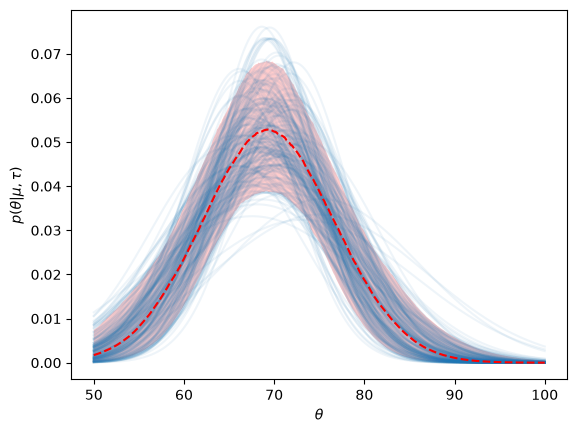

In [15]:
xvals = np.linspace(50, 100, num=1000)
n_draws = 1000
p_thetas = np.zeros((n_draws, xvals.size))
for ii in range(n_draws):
    idx = np.random.randint(0, num_samples)
    if ii % 5 == 0:
        plt.plot(xvals, np.exp(dist.Normal(samples['mu'][idx], 10**samples['log_tau'][idx]).log_prob(xvals)),
            c='C0', alpha=0.075)
    p_thetas[ii] = np.exp(dist.Normal(samples['mu'][idx], 10**samples['log_tau'][idx]).log_prob(xvals))
hyperprior_median, five, ninetyfive = np.percentile(p_thetas, [50, 5, 95], axis=0)    
plt.plot(xvals, hyperprior_median, c='r', ls='--')
plt.fill_between(xvals, five, ninetyfive, facecolor='r', alpha=0.2)
plt.xlabel("$\\theta$")
plt.ylabel("$p(\\theta | \\mu, \\tau)$")
plt.show()

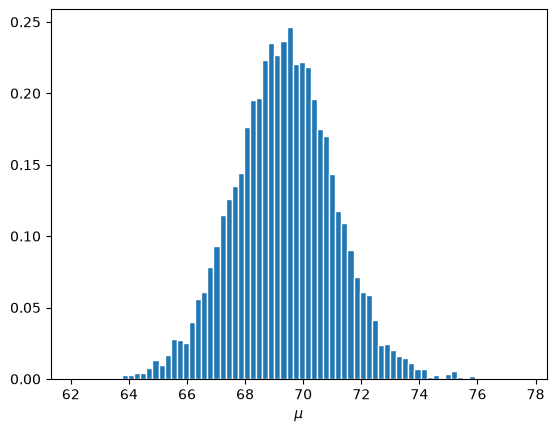

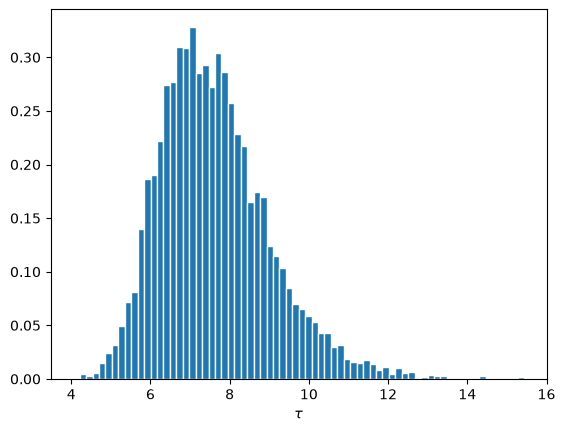

In [16]:
plt.hist(samples['mu'], density=True, bins='auto', edgecolor='w')
plt.xlabel("$\\mu$")
plt.show()
plt.hist(10**samples['log_tau'], density=True, bins='auto', edgecolor='w')
plt.xlabel("$\\tau$")
plt.show()

## Posteriors on individual $\theta_j$'s

We can also look at posteriors on the individual $\theta_j$'s, and compare them to what one would get if we used a simple, flat prior. 

There are a couple of ways to do this. With a broad, constant prior, the posterior becomes analytic---it is a Gaussian. We show how to calculate it below, but it is easily derivable and is simply an inverse-noise-weighted sum (just like we saw for linear regression last week). 

With no population prior, each city is analyzed independently. The populatin prior is what links them together. That's why we see that for cases where the mean scores are in the tails the population prior *pulls those values back towards the center*. This is known as "shrinkage". 

In [17]:
def naive_posteriors(scores, score_variances):
    variances = np.sum(1 / score_variances, axis=1) ** -1
    means = np.sum(scores / score_variances, axis=1) * variances
    return means, variances

In [18]:
city_means, city_variances = naive_posteriors(scores, score_variances)

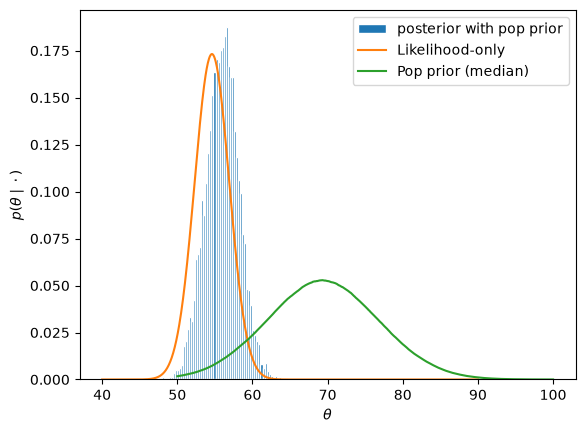

In [19]:
idx = 2 # change to see effect on different averages
plt.hist(samples['theta_js'][:, idx], bins='auto', density=True, edgecolor='w', label='posterior with pop prior')
local_xvals = np.linspace(40, 90, num=1000)
plt.plot(local_xvals,
         np.exp(dist.Normal(city_means[idx], city_variances[idx]**0.5).log_prob(local_xvals)), 
        label='Likelihood-only')
plt.plot(xvals, hyperprior_median, label='Pop prior (median)')
plt.xlabel("$\\theta$")
plt.ylabel("$p(\\theta \\mid \\cdot)$")
plt.legend()
plt.show()

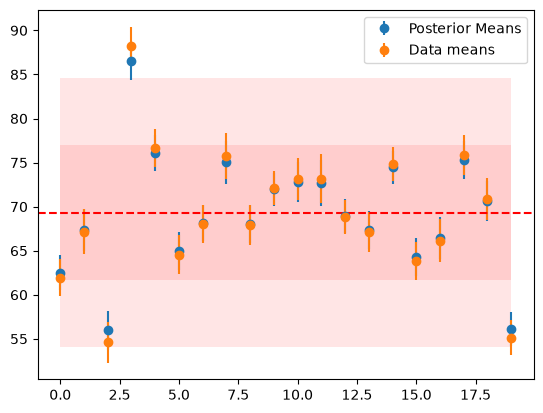

In [20]:
plt.errorbar(np.arange(n_city), np.mean(samples['theta_js'], axis=0), yerr=np.std(samples['theta_js'], axis=0), fmt='o', label='Posterior Means')
plt.errorbar(np.arange(n_city), city_means, yerr=np.sqrt(city_variances), fmt='o', label='Data means')
plt.fill_between(np.arange(n_city), np.mean(samples['mu']) - np.mean(10**samples['log_tau']), 
                 np.mean(samples['mu']) + np.mean(10**samples['log_tau']), facecolor='r', alpha=0.1)
plt.fill_between(np.arange(n_city), np.mean(samples['mu']) - 2*np.mean(10**samples['log_tau']), 
                 np.mean(samples['mu']) + 2*np.mean(10**samples['log_tau']), facecolor='r', alpha=0.1)
ax = plt.gca()
ax.axhline(np.mean(samples['mu']), c='r', ls='--')
plt.legend()
plt.show()

In [21]:
mcmc_wider_noise = infer.MCMC(kernel, num_warmup=5000, num_samples=num_samples)

# Let's fully corrupt one city and see what happens now

If we artificially increase the variance on all of the data in a single city, let's see what
happens to our posterior on that city.

In [22]:
score_sigmas_corrupted = np.copy(score_sigmas)
score_sigmas_corrupted[0, :] = 100 # corrupt the first city. likelihood will be quite uninformative now
mcmc_wider_noise.run(jax.random.key(0), scores, score_sigmas_corrupted)

sample: 100%|████████| 15000/15000 [00:03<00:00, 4398.65it/s, 15 steps of size 2.47e-01. acc. prob=0.91]


In [23]:
score_sigmas_corrupted.shape

(20, 10)

In [24]:
mcmc_wider_noise.print_summary()


                        mean       std    median      5.0%     95.0%     n_eff     r_hat
           log_tau      0.87      0.08      0.87      0.74      1.00   1918.32      1.00
                mu     69.67      1.85     69.69     66.69     72.74   1607.64      1.00
 theta_js_dummy[0]     -0.04      0.96     -0.04     -1.65      1.53  13169.52      1.00
 theta_js_dummy[1]     -0.31      0.39     -0.31     -0.96      0.32   4050.72      1.00
 theta_js_dummy[2]     -1.85      0.46     -1.84     -2.58     -1.07   3083.99      1.00
 theta_js_dummy[3]      2.29      0.50      2.27      1.50      3.15   2375.95      1.00
 theta_js_dummy[4]      0.87      0.38      0.86      0.27      1.52   2646.01      1.00
 theta_js_dummy[5]     -0.63      0.38     -0.62     -1.27     -0.01   3507.93      1.00
 theta_js_dummy[6]     -0.20      0.36     -0.20     -0.78      0.40   3151.49      1.00
 theta_js_dummy[7]      0.73      0.41      0.72      0.06      1.38   3588.85      1.00
 theta_js_dummy[8]  

In [25]:
samples_wider_noise = mcmc_wider_noise.get_samples()

The prior on the theta's does'nt change much, because we essentilly only removed one city

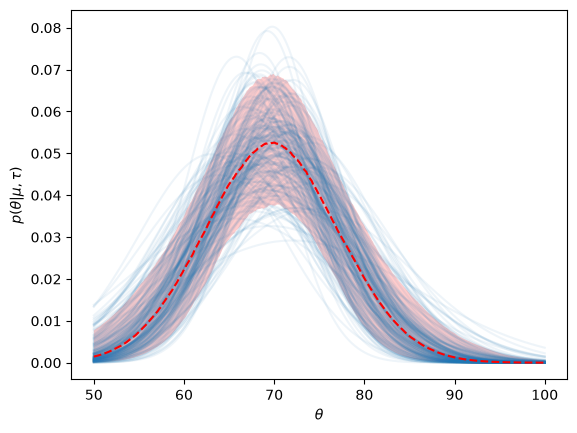

In [26]:
xvals = np.linspace(50, 100, num=1000)
n_draws = 1000
p_thetas = np.zeros((n_draws, xvals.size))
for ii in range(n_draws):
    idx = np.random.randint(0, num_samples)
    if ii % 5 == 0:
        plt.plot(xvals, np.exp(dist.Normal(samples_wider_noise['mu'][idx], 10**samples_wider_noise['log_tau'][idx]).log_prob(xvals)),
            c='C0', alpha=0.075)
    p_thetas[ii] = np.exp(dist.Normal(samples_wider_noise['mu'][idx], 10**samples_wider_noise['log_tau'][idx]).log_prob(xvals))
hyperprior_median, five, ninetyfive = np.percentile(p_thetas, [50, 5, 95], axis=0)    
plt.plot(xvals, hyperprior_median, c='r', ls='--')
plt.fill_between(xvals, five, ninetyfive, facecolor='r', alpha=0.2)
plt.xlabel("$\\theta$")
plt.ylabel("$p(\\theta | \\mu, \\tau)$")
plt.show()

In [27]:
city_means_wider, city_variances_wider = naive_posteriors(scores, score_sigmas_corrupted**2)

But if we now look at the **individual** posteriors on the individual $\theta_j$ we see that the independently analyzed data (orange)
and the posterior that includes the population prior (blue) for the first city now disagree more than the other points. Let's look at that point more closely 

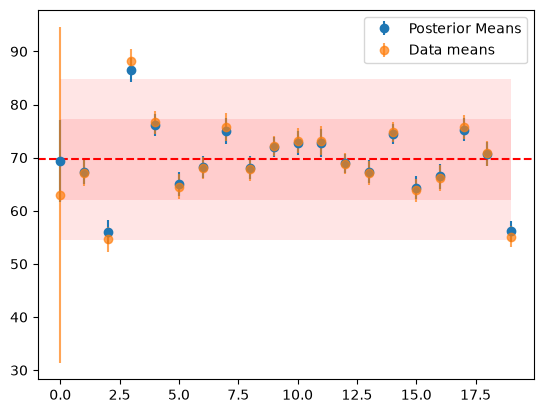

In [28]:
plt.errorbar(np.arange(n_city), np.mean(samples_wider_noise['theta_js'], axis=0), yerr=np.std(samples_wider_noise['theta_js'], axis=0), fmt='o', label='Posterior Means')
plt.errorbar(np.arange(n_city), city_means_wider, yerr=np.sqrt(city_variances_wider), fmt='o', label='Data means', alpha=0.7)
plt.fill_between(np.arange(n_city), np.mean(samples_wider_noise['mu']) - np.mean(10**samples_wider_noise['log_tau']), 
                 np.mean(samples_wider_noise['mu']) + np.mean(10**samples_wider_noise['log_tau']), facecolor='r', alpha=0.1)
plt.fill_between(np.arange(n_city), np.mean(samples_wider_noise['mu']) - 2*np.mean(10**samples_wider_noise['log_tau']), 
                 np.mean(samples_wider_noise['mu']) + 2*np.mean(10**samples_wider_noise['log_tau']), facecolor='r', alpha=0.1)
ax = plt.gca()
ax.axhline(np.mean(samples_wider_noise['mu']), c='r', ls='--')
plt.legend()
plt.show()

### The posterior on $\theta_j$ is just the (population) prior

Now the posterior on $\theta_j$ just returns the population prior. We are now saying "based on the other cities' data, we think it shoudl be this because the data for this city is so uninformative"

Indeed, the orange shows the posterior on $\theta_j$ if we didn't include the population prior and used something uninformative instead. In that case, we get something very broad because the data
are not very good. 

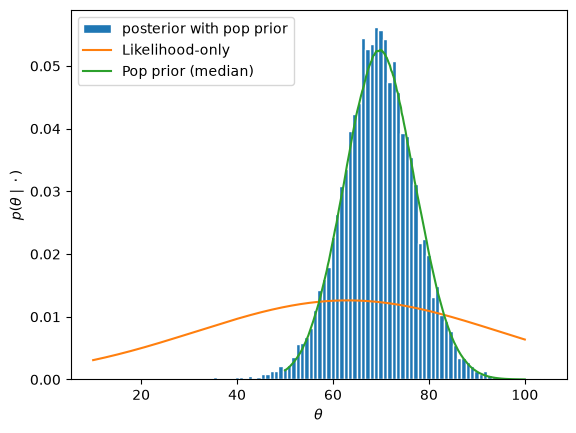

In [29]:
idx = 0 # change to see effect on different averages
plt.hist(samples_wider_noise['theta_js'][:, idx], bins='auto', density=True, edgecolor='w', label='posterior with pop prior')
local_xvals = np.linspace(10, 100, num=1000)
plt.plot(local_xvals,
         np.exp(dist.Normal(city_means_wider[idx], city_variances_wider[idx]**0.5).log_prob(local_xvals)), 
        label='Likelihood-only')
plt.plot(xvals, hyperprior_median, label='Pop prior (median)')
plt.xlabel("$\\theta$")
plt.ylabel("$p(\\theta \\mid \\cdot)$")
plt.legend()
plt.show()